Loading the Dataset from Kaggle

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("ninadaithal/imagesoasis")
path=path+"/Data"
print("Path to dataset files:", path)

100%|██████████| 1.23G/1.23G [00:15<00:00, 86.9MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/ninadaithal/imagesoasis/versions/1/Data


In [ ]:
import os
import pandas as pd

In [ ]:
os.listdir(path)

['Very mild Dementia', 'Non Demented', 'Moderate Dementia', 'Mild Dementia']

Processing the dataset to create a dataframe

In [ ]:
imgs_path=[]
files = os.listdir(path)
for data in files:
  imgs_tmp=os.listdir(path+'/'+data)
  for i in imgs_tmp:
    imgs_path.append(path+'/'+data+'/'+i)
df=pd.DataFrame({"img_path":imgs_path})
df

,img_path
0,/root/.cache/kagglehub/datasets/ninadaithal/im...
1,/root/.cache/kagglehub/datasets/ninadaithal/im...
2,/root/.cache/kagglehub/datasets/ninadaithal/im...
3,/root/.cache/kagglehub/datasets/ninadaithal/im...
4,/root/.cache/kagglehub/datasets/ninadaithal/im...
...,...
86432,/root/.cache/kagglehub/datasets/ninadaithal/im...
86433,/root/.cache/kagglehub/datasets/ninadaithal/im...
86434,/root/.cache/kagglehub/datasets/ninadaithal/im...
86435,/root/.cache/kagglehub/datasets/ninadaithal/im...


In [ ]:
import re
def extract_data_from_path(s):
  classes={'Non Demented':0, 'Very mild Dementia':1, 'Moderate Dementia':2, 'Mild Dementia':3}
  match = re.search(
      r'Data/(.*?)/OAS1_(\d+)_MR(\d+)_mpr-(\d+)_(\d+)\.jpg$',s)
  values = match.groups()
  values=list(values)
  values[0]=classes[values[0]]
  values=tuple(values)
  return values
extract_data_from_path("/root/.cache/kagglehub/datasets/ninadaithal/imagesoasis/versions/1/Data/Non Demented/OAS1_0336_MR1_mpr-2_130.jpg")

(0, '0336', '1', '2', '130')

In [ ]:
df['label'], df['patient_ID'], df['MRI_ID'],df['MRP_ID'],df["slice_no"] = zip(*df['img_path'].apply(extract_data_from_path))

In [ ]:
df['patient_ID'].unique()

array(['0155', '0312', '0307', '0060', '0329', '0247', '0066', '0243',
       '0164', '0124', '0161', '0022', '0217', '0041', '0304', '0300',
       '0210', '0380', '0263', '0233', '0287', '0082', '0267', '0142',
       '0288', '0015', '0335', '0046', '0098', '0205', '0039', '0094',
       '0272', '0290', '0179', '0115', '0352', '0374', '0273', '0003',
       '0021', '0240', '0226', '0158', '0339', '0298', '0123', '0166',
       '0315', '0238', '0362', '0023', '0042', '0120', '0016', '0143',
       '0084', '0286', '0359', '0182', '0092', '0319', '0054', '0224',
       '0372', '0062', '0047', '0303', '0049', '0202', '0218', '0256',
       '0190', '0107', '0236', '0080', '0207', '0295', '0153', '0131',
       '0317', '0366', '0270', '0232', '0234', '0117', '0285', '0071',
       '0176', '0343', '0264', '0327', '0152', '0197', '0037', '0221',
       '0018', '0074', '0059', '0231', '0191', '0168', '0170', '0200',
       '0326', '0311', '0004', '0198', '0239', '0213', '0072', '0314',
      

In [ ]:
patient_ids=df["patient_ID"].unique()
per_patient_database=dict()
for id in patient_ids:
  per_patient_database[id]=df[df["patient_ID"]==id].copy(deep=True)

In [ ]:
len(per_patient_database)

347

In [ ]:
import random
patients_train=[]
patients_test=[]
for i in patient_ids:
  if random.random()>=0.95:
    patients_test.append(i)
  else:
    patients_train.append(i)
print(len(patients_test))
print(len(patients_train))

16
331


In [ ]:
!pip install opencv-python
import cv2

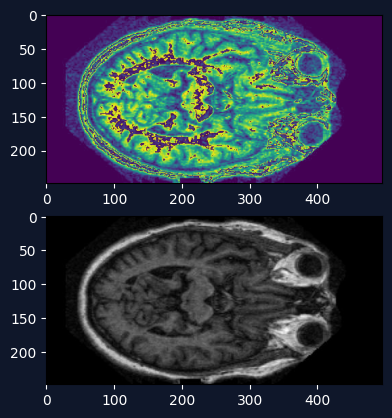

In [ ]:
path=per_patient_database[patients_train[0]]["img_path"].iloc[6]

img = cv2.imread(path)
new_img=(img[:,:,0]+img[:,:,1]+img[:,:,2])/3
import matplotlib.pyplot as plt
fig,axs=plt.subplots(2,1, facecolor="#0f172a")
img_to_see=[new_img,img]
counter=0
for ax in axs.flat:
  ax.set_facecolor("#0f172a")
  ax.imshow(img_to_see[counter])
  ax.tick_params(colors="white")
  counter+=1
plt.show()

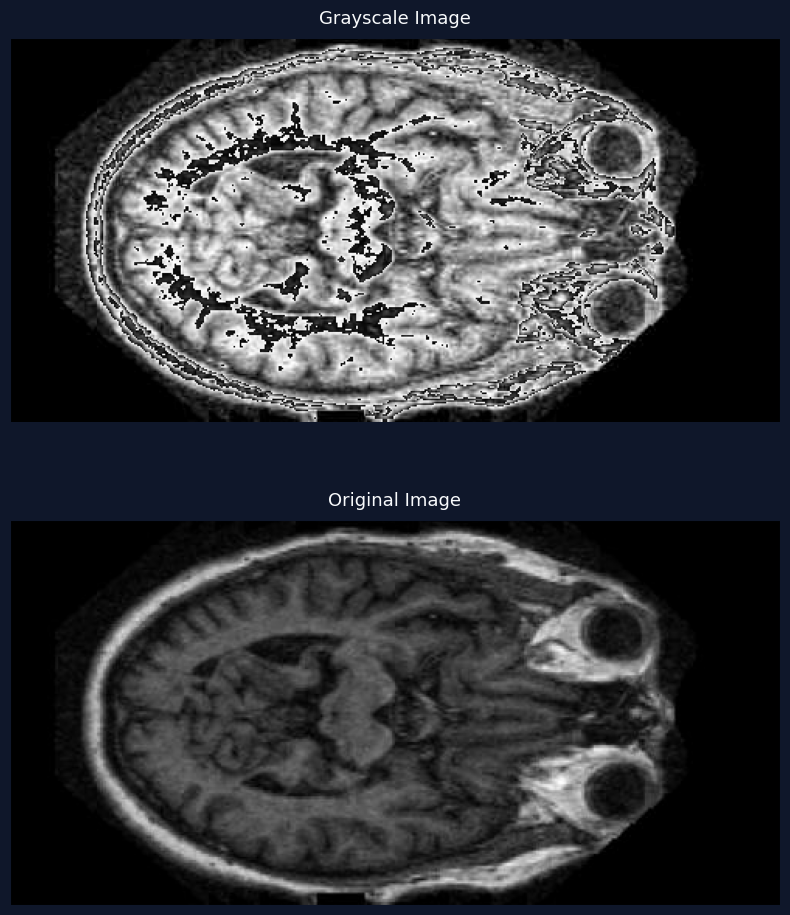

In [ ]:

import cv2
import matplotlib.pyplot as plt

path = per_patient_database[patients_train[0]]["img_path"].iloc[6]

img = cv2.imread(path)

# Convert to grayscale by averaging the three channels
new_img = (img[:, :, 0] + img[:, :, 1] + img[:, :, 2]) / 3

# Colors
bg_color = "#0f172a"
text_color = "#f8fafc"

# Create figure with matching background
fig, axs = plt.subplots(2, 1, figsize=(8, 10))
fig.patch.set_facecolor(bg_color)

img_to_see = [new_img, cv2.cvtColor(img, cv2.COLOR_BGR2RGB)]
titles = ["Grayscale Image", "Original Image"]

for ax, image, title in zip(axs.flat, img_to_see, titles):
    ax.set_facecolor(bg_color)

    if title == "Grayscale Image":
        ax.imshow(image, cmap="gray")
    else:
        ax.imshow(image)

    ax.set_title(title, color=text_color, fontsize=13, pad=10)
    ax.tick_params(colors=text_color)

    # Hide axes for a cleaner image display
    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_color(bg_color)

plt.tight_layout()
plt.show()

(248, 496)


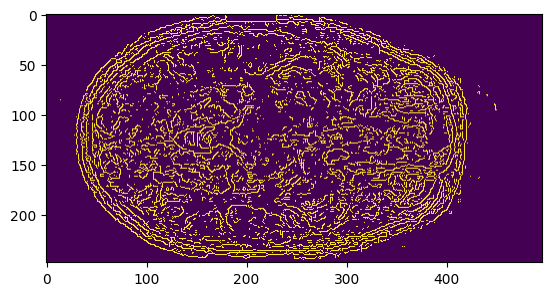

In [ ]:
edges=cv2.Canny(img,95,100)
print(edges.shape)
plt.imshow(edges)
plt.show()

Data Preprocessing

In [ ]:
import os
import re
import cv2
import numpy as np
import pandas as pd

from scipy.stats import skew, kurtosis

from skimage.feature import (
    hog,
    local_binary_pattern,
    graycomatrix,
    graycoprops
)
from skimage.measure import moments_hu

Constants

In [ ]:
IMAGE_SIZE=(224,224)

#HOG parameters
HOG_ORIENTATIONS=9
HOG_PIXELS_PER_CELL=(16,16)
HOG_CELLS_PER_BLOCK=(2,2)

#LBP parameters
LBP_RADIUS=2
LBP_POINTS=8*LBP_RADIUS

# GLCM parameters
GLCM_DISTANCES = [1, 2, 3]
GLCM_ANGLES = [0,np.pi / 4,np.pi / 2,3 * np.pi / 4]

# Number of gray levels for GLCM
GLCM_LEVELS = 32

In [ ]:
def preprocess_image(img_path):
  image=cv2.imread(img_path,cv2.IMREAD_GRAYSCALE)
  # Resize
  image=cv2.resize(image,IMAGE_SIZE,interpolation=cv2.INTER_AREA)
  # Gaussian denoising
  image=cv2.GaussianBlur(image,(5,5),0)
  # CLAHE
  clahe=cv2.createCLAHE(clipLimit=2.0,tileGridSize=(8,8))
  image=clahe.apply(image)
  # Normalizing
  image=cv2.normalize(image,None,alpha=0,beta=255,norm_type=cv2.NORM_MINMAX)
  return image.astype(np.uint8)


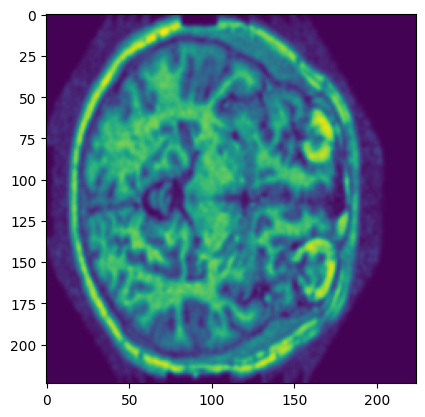

In [ ]:
image=preprocess_image(path)
plt.imshow(image)
plt.show()

Intensity feature extractor

In [ ]:
def extract_intensity_features(image):
  pixels=image.astype(np.float32).flatten()
  features=dict()
  features['intensity_mean']=np.mean(pixels)
  features['intensity_std']=np.std(pixels)
  features['intensity_min']=np.min(pixels)
  features['intensity_max']=np.max(pixels)
  features['intensity_median']=np.median(pixels)
  features["intensity_q25"] = np.percentile(pixels, 25)
  features["intensity_q75"] = np.percentile(pixels, 75)
  features["intensity_skewness"] = skew(pixels)
  features["intensity_kurtosis"] = kurtosis(pixels)

  # Entropy
  histogram=np.histogram(pixels,bins=256,range=(0,255),density=True)[0]
  histogram=histogram[histogram>0]
  features['intensity_entropy']=-np.sum(histogram*np.log2(histogram))
  return features

HOG FEATURES

In [ ]:
def extract_hog_features(image):
  hog_features=hog(
      image,
      orientations=HOG_ORIENTATIONS,
      pixels_per_cell=HOG_PIXELS_PER_CELL,
      cells_per_block=HOG_CELLS_PER_BLOCK,
      block_norm="L2-Hys",
      feature_vector=True
  )
  return {
      f"hog_{i}":value for i,value in enumerate(hog_features)
  }

UNIFORM LBP FEATURES

In [ ]:
def extract_lbp_features(image):
  lbp=local_binary_pattern(image,P=LBP_POINTS,R=LBP_RADIUS,method="uniform")
  n_bins=LBP_POINTS+2
  histogram,_=np.histogram(lbp.ravel(),bins=n_bins,range=(0,n_bins))
  #Normalize histograms
  histogram=histogram.astype(np.float32)
  histogram/=(histogram.sum()+1e-10)
  return {
      f"lbp_{i}":value
      for i,value in enumerate(histogram)
  }

GLCM FEATURES

In [ ]:
def quantize_image(image,levels=32):
  quantized=(image.astype(np.float32)/256*levels).astype(np.uint8)
  quantized[quantized>=levels]=levels-1
  return quantized

def extract_glcm_features(image):
  image_quantized=quantize_image(image,GLCM_LEVELS)
  glcm=graycomatrix(
      image_quantized,
      distances=GLCM_DISTANCES,
      angles=GLCM_ANGLES,
      levels=GLCM_LEVELS,
      symmetric=True,
      normed=True
  )
  features=dict()
  properties=[
      "contrast",
      "dissimilarity",
      "homogeneity",
      "energy",
      "correlation",
      "ASM"
  ]
  for prop in properties:
    values=graycoprops(glcm,prop)
    # Average over distances and angles
    mean_value=np.mean(values)
    features[f"glcm_{prop}"]=mean_value

    # Also retain standard deviation
    features[f"glcm_{prop}_std"]=np.std(values)

  return features


CANNY EDGE FEATURES

In [ ]:
def extract_canny_features(image):
  edges=cv2.Canny(image,50,150)
  features={}
  # Edge density
  edge_pixels=np.sum(edges>0)
  total_pixels=edges.size
  edge_density=edge_pixels/total_pixels
  features["canny_edge_density"]=edge_density
  # Number of contours
  contours,_=cv2.findContours(edges,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
  features["canny_contour_count"]=len(contours)
  # Contour statistics
  if len(contours)>0:
    areas=np.array([cv2.contourArea(c) for c in contours])
    perimeters=np.array([cv2.arcLength(c,True) for c in contours])
    features["contour_area_mean"]=np.mean(areas)
    features["contour_area_std"]=np.std(areas)
    features["contour_area_max"]=np.max(areas)
    features["contour_perimeter_mean"]=np.mean(perimeters)
    features["contour_perimeter_std"]=np.std(perimeters)
    features["contour_perimeter_max"]=np.max(perimeters)
  else:
    features["contour_area_mean"]=0
    features["contour_area_std"]=0
    features["contour_area_max"]=0
    features["contour_perimeter_mean"]=0
    features["contour_perimeter_std"]=0
    features["contour_perimeter_max"]=0
  # Edge density by spatial region
  h,w=edges.shape
  grid_size=4
  region_index=0
  for row in range(grid_size):
    for col in range(grid_size):
      y1=row*h//grid_size
      y2=(row+1)*h//grid_size

      x1=col*w//grid_size
      x2=(col+1)*w//grid_size
      region=edges[y1:y2,x1:x2]
      density=np.mean(region>0)
      features[f"canny_region_density_{region_index}"]=density
      region_index+=1
  return features


HU moments

In [ ]:
def extract_hu_features(image):
  _,binary=cv2.threshold(image,0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)
  moments=cv2.moments(binary)
  hu=cv2.HuMoments(moments).flatten()
  features=dict()
  for i,value in enumerate(hu):
    if value!=0:
      value=-np.sign(value)*np.log10(abs(value))
      features[f"hu_{i+1}"]=value
  return features

Brain geometry

In [ ]:
def get_brain_mask(image):
  if image.dtype!=np.uint8:
    image=cv2.normalize(image,None,0,255,cv2.NORM_MINIMAX).astype(np.uint8)
  # Otsu threshold
  _,mask=cv2.threshold(image,0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)
  # Remove small noise
  kernel=np.ones((5,5),np.uint8)
  mask=cv2.morphologyEx(mask,cv2.MORPH_OPEN,kernel)
  mask=cv2.morphologyEx(mask,cv2.MORPH_CLOSE,kernel)
  # Find connected components
  num_labels,labels,stats,_=cv2.connectedComponentsWithStats(mask,connectivity=8)
  if num_labels<=1:
    return np.zeros_like(mask,dtype=np.uint8)
  # Ignore background (label 0)
  largest_label=1+np.argmax(stats[1:,cv2.CC_STAT_AREA])
  brain_mask=(labels==largest_label).astype(np.uint8)
  return brain_mask

def extract_brain_geometry(image,brain_mask):
  features=dict()
  h,w=image.shape
  brain_area=np.sum(brain_mask)
  features["brain_area"]=float(brain_area)
  # Fraction of image occupied by brain
  features["brain_occupancy"]=float(brain_area/(h*w))
  if brain_area==0:
        return {
            "brain_area":0.0,
            "brain_occupancy":0.0,
            "brain_bbox_width":0.0,
            "brain_bbox_height":0.0,
            "brain_aspect_ratio":0.0,
            "brain_centroid_x":0.0,
            "brain_centroid_y":0.0
        }
  # Bounding box
  ys,xs=np.where(brain_mask>0)
  x_min=xs.min()
  x_max=xs.max()
  y_min=ys.min()
  y_max=ys.max()
  bbox_width=x_max-x_min+1
  bbox_height=y_max-y_min+1
  features["brain_bbox_width"]=float(bbox_width)
  features["brain_bbox_height"]=float(bbox_height)
  features["brain_aspect_ratio"]=float(bbox_width/bbox_height)
  # Centroid
  M=cv2.moments(brain_mask.astype(np.uint8))
  if M["m00"]!=0:
    cx=M["m10"]/M["m00"]
    cy=M["m01"]/M["m00"]
  else:
    cx=0
    cy=0
  # Normalize centroid to [0,1]
  features["brain_centroid_x"]=float(cx/w)
  features["brain_cantroid_y"]=float(cy/h)
  return features


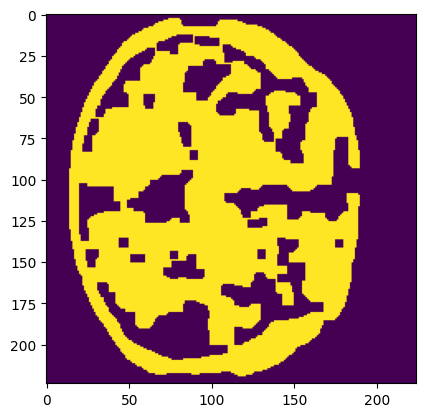

In [ ]:
mask=get_brain_mask(image)
plt.imshow(mask)
plt.show()

In [ ]:
def extract_hemisphere_features(image,brain_mask):
  features=dict()
  h,w=image.shape
  mid=w//2
  left_mask=brain_mask[:,:mid]
  right_mask=brain_mask[:,mid:]
  left_image=image[:,:mid]
  right_image=image[:,mid:]
  left_area=np.sum(left_mask)
  right_area=np.sum(right_mask)
  features['left_brain_area']=float(left_area)
  features['right_brain_area']=float(right_area)
  total=left_area+right_area
  if total>0:
    features['left_brain_fraction']=float(left_area/total)
    features['right_brain_fraction']=float(right_area/total)
    features['brain_area_asymmetry']=float(abs(left_area-right_area)/total)
  else:
    features['left_brain_fraction']=0.0
    features['right_brain_fraction']=0.0
    features['brain_area_asymmetry']=0.0
  left_mean=0
  right_mean=0
  # Mean intensity in each hemisphere
  left_pixels=left_image[left_mask>0]
  right_pixels=right_image[right_mask>0]
  if len(left_pixels)>0:
    left_mean=np.mean(left_pixels)
  if len(right_pixels)>0:
    right_mean=np.mean(right_pixels)
  features['left_mean_intensity']=float(left_mean)
  features['right_mean_intensity']=float(right_mean)
  if left_mean+right_mean>0:
    features["intensity_asymmetry"]=float(abs(left_mean-right_mean)/((left_mean+right_mean)/2))
  else:
    features["intensity_asymmetry"]=0.0
  return features


CSF/atrophy-related proxies

In [ ]:
def extract_csf_atrophy_proxies(image,brain_mask):
  features=dict()
  brain_pixels=image[brain_mask>0]
  if len(brain_pixels)==0:
    return {
        "low_intensity_ratio":0.0,
        "very_low_intensity_ratio":0.0,
        "central_low_intensity_ratio":0.0,
        "brain_intensity_mean":0.0,
        "brain_intensity_std":0.0
    }

  # Calculate thresholds relative to this image
  p25=np.percentile(brain_pixels,25)
  p10=np.percentile(brain_pixels,10)
  low_mask=(image<=p25)&(brain_mask>0)
  very_low_mask=(image<=p10)&(brain_mask>0)
  brain_area=np.sum(brain_mask)
  features["low_intensity_ratio"]=float(np.sum(low_mask)/brain_area)
  features["very_low_intensity_ratio"]=float(np.sum(very_low_mask)/brain_area)

  # Central region (May need to change later)
  h,w=image.shape
  x1=int(0.25*w)
  x2=int(0.75*w)
  y1=int(0.2*h)
  y2=int(0.8*h)

  central_mask=np.zeros_like(brain_mask)
  central_mask[y1:y2,x1:x2]=1
  central_brain=(brain_mask>0)&(central_mask>0)
  central_area=np.sum(central_brain)
  if central_area>0:
    central_low=(image<=p25) & central_brain
    features["central_low_intensity_ratio"]=float(np.sum(central_low)/central_area)
  else:
    features["central_low_intensity_ratio"] = 0.0

  features["brain_intensity_mean"] = float(
      np.mean(brain_pixels)
  )

  features["brain_intensity_std"] = float(
      np.std(brain_pixels)
  )

  return features


In [ ]:
def extract_ventricular_proxy(image, brain_mask):
    """
    Estimate ventricular-space proxies from the central brain region.

    IMPORTANT:
    These are heuristic 2D proxies, NOT actual ventricle segmentation.
    """

    features = {}

    h, w = image.shape

    # Central ROI
    x1 = int(0.30 * w)
    x2 = int(0.70 * w)

    y1 = int(0.25 * h)
    y2 = int(0.75 * h)

    roi_mask = np.zeros_like(brain_mask)
    roi_mask[y1:y2, x1:x2] = 1

    central_brain = (
        (brain_mask > 0) &
        (roi_mask > 0)
    )

    central_pixels = image[central_brain > 0]

    if len(central_pixels) == 0:
        return {
            "ventricular_proxy_area": 0.0,
            "ventricular_proxy_ratio": 0.0,
            "left_ventricular_proxy_area": 0.0,
            "right_ventricular_proxy_area": 0.0,
            "ventricular_asymmetry": 0.0
        }

    # Use a relative threshold
    threshold = np.percentile(
        central_pixels,
        15
    )

    dark_mask = (
        (image <= threshold) &
        central_brain
    ).astype(np.uint8)

    # Remove tiny noise
    kernel = np.ones((3, 3), np.uint8)

    dark_mask = cv2.morphologyEx(
        dark_mask,
        cv2.MORPH_OPEN,
        kernel
    )

    dark_mask = cv2.morphologyEx(
        dark_mask,
        cv2.MORPH_CLOSE,
        kernel
    )

    # Connected components
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
        dark_mask,
        connectivity=8
    )

    component_areas = []

    for label in range(1, num_labels):

        area = stats[label, cv2.CC_STAT_AREA]

        # Ignore tiny components
        if area >= 5:
            component_areas.append(
                (label, area)
            )

    if len(component_areas) == 0:
        ventricular_area = 0
    else:
        # Use the largest few dark components
        component_areas.sort(
            key=lambda x: x[1],
            reverse=True
        )

        largest_components = component_areas[:4]

        ventricular_area = sum(
            area for _, area in largest_components
        )

    central_brain_area = np.sum(central_brain)

    if central_brain_area > 0:
        ventricular_ratio = (
            ventricular_area /
            central_brain_area
        )
    else:
        ventricular_ratio = 0

    features["ventricular_proxy_area"] = float(
        ventricular_area
    )

    features["ventricular_proxy_ratio"] = float(
        ventricular_ratio
    )

    # Left/right ventricular proxy
    mid = w // 2

    left_dark = dark_mask[:, :mid]
    right_dark = dark_mask[:, mid:]

    left_area = np.sum(left_dark)
    right_area = np.sum(right_dark)

    features["left_ventricular_proxy_area"] = float(
        left_area
    )

    features["right_ventricular_proxy_area"] = float(
        right_area
    )

    total = left_area + right_area

    if total > 0:
        features["ventricular_asymmetry"] = float(
            abs(left_area - right_area) / total
        )
    else:
        features["ventricular_asymmetry"] = 0.0

    return features

In [ ]:
def extract_cortical_proxy(image, brain_mask):
    """
    Extract structural boundary / sulcal proxies.

    These do NOT measure cortical thickness directly.
    """

    features = {}

    # Canny edges
    edges = cv2.Canny(
        image,
        50,
        150
    )

    # Only consider edges inside brain
    brain_edges = (
        (edges > 0) &
        (brain_mask > 0)
    )

    brain_area = np.sum(brain_mask)

    if brain_area > 0:

        features["brain_edge_density"] = float(
            np.sum(brain_edges) / brain_area
        )

    else:

        features["brain_edge_density"] = 0.0

    # Find boundary of brain
    contours, _ = cv2.findContours(
        brain_mask.astype(np.uint8),
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    if len(contours) == 0:

        features["brain_boundary_perimeter"] = 0.0
        features["brain_boundary_area"] = 0.0
        features["brain_boundary_complexity"] = 0.0
        features["boundary_edge_density"] = 0.0

        return features

    # Largest contour
    contour = max(
        contours,
        key=cv2.contourArea
    )

    perimeter = cv2.arcLength(
        contour,
        True
    )

    area = cv2.contourArea(contour)

    features["brain_boundary_perimeter"] = float(
        perimeter
    )

    features["brain_boundary_area"] = float(
        area
    )

    # Shape complexity
    if area > 0:

        features["brain_boundary_complexity"] = float(
            (perimeter ** 2) / (4 * np.pi * area)
        )

    else:

        features["brain_boundary_complexity"] = 0.0

    # Create a thin band just inside brain boundary
    kernel = np.ones((9, 9), np.uint8)

    eroded = cv2.erode(
        brain_mask.astype(np.uint8),
        kernel
    )

    boundary_band = (
        (brain_mask > 0) &
        (eroded == 0)
    )

    boundary_edges = (
        (edges > 0) &
        boundary_band
    )

    boundary_area = np.sum(boundary_band)

    if boundary_area > 0:

        features["boundary_edge_density"] = float(
            np.sum(boundary_edges) /
            boundary_area
        )

    else:

        features["boundary_edge_density"] = 0.0

    return features

Putting them all together

In [ ]:
def extract_all_features(image_path):
  image=preprocess_image(image_path)
  features=dict()
  #------------------------ Image-based feature extraction ------------------------
  # Intensity
  features.update(extract_intensity_features(image))
  # HOG
  features.update(extract_hog_features(image))
  # LBP
  features.update(extract_lbp_features(image))
  # GLCM
  features.update(extract_glcm_features(image))
  # Canny
  features.update(extract_canny_features(image))
  # Hu moments
  features.update(extract_hu_features(image))

  #------------------------ Brain-based feature extraction ------------------------
  # brain mask
  brain_mask = get_brain_mask(image)
  # Brain Geometry
  features.update(extract_brain_geometry(image,brain_mask))
  # Brain left-right asymmetry
  features.update(extract_hemisphere_features(image,brain_mask))
  # CSF / atrophy proxies
  features.update(extract_csf_atrophy_proxies(image,brain_mask))
  # Ventricular proxy
  features.update(extract_ventricular_proxy(image,brain_mask))
  # Cortical / sulcal proxy
  features.update(extract_cortical_proxy(image,brain_mask))

  return features

In [ ]:
entire_dataset=[]
for patient_id in per_patient_database:
  df=per_patient_database[patient_id]
  r,_=df.shape
  slice_features=[]
  for i in range(r):
    img_path=df.iloc[i]["img_path"]
    label=df.iloc[i]['label']
    features=extract_all_features(img_path)
    features['label']=label
    slice_features.append(features)
    del features
  feature_df=pd.DataFrame(slice_features)
  patient_features={}
  patient_features["patient_id"]=patient_id
  for feature in feature_df.columns:
        values=feature_df[feature].values
        patient_features[feature]=np.mean(values)
  entire_dataset.append(patient_features)
  del patient_features
  del feature_df
data=pd.DataFrame(entire_dataset)
del entire_dataset
data

/tmp/ipykernel_2423/1582167624.py:137: RuntimeWarning: overflow encountered in scalar subtract
  abs(left_area - right_area) / total
/tmp/ipykernel_2423/3150108063.py:17: RuntimeWarning: overflow encountered in scalar subtract
  features['brain_area_asymmetry']=float(abs(left_area-right_area)/total)


,patient_id,intensity_mean,intensity_std,intensity_min,intensity_max,intensity_median,intensity_q25,intensity_q75,intensity_skewness,intensity_kurtosis,...,ventricular_proxy_ratio,left_ventricular_proxy_area,right_ventricular_proxy_area,ventricular_asymmetry,brain_edge_density,brain_boundary_perimeter,brain_boundary_area,brain_boundary_complexity,boundary_edge_density,label
0,0074,74.536346,65.992699,0.0,255.0,63.965164,9.516394,128.340164,0.492234,-0.943436,...,0.043391,274.524590,344.344262,1.956985e+16,0.224113,902.739902,28345.942623,2.837147,0.262853,0.0
1,0322,60.870819,61.428112,0.0,255.0,38.108608,7.180328,102.717216,0.921108,-0.121252,...,0.035447,193.790984,195.237705,2.939090e+16,0.245404,1286.574825,19667.911885,8.610363,0.268897,0.0
2,0007,72.912498,67.210175,0.0,255.0,60.495903,1.907787,128.573776,0.487911,-1.055544,...,0.039205,234.459016,387.295082,2.179000e+16,0.224036,857.629604,27635.368852,2.452273,0.265789,0.0
3,0150,69.515465,68.084000,0.0,255.0,49.255123,1.393443,123.980019,0.613287,-0.965298,...,0.040122,248.918033,393.325820,2.371935e+16,0.215625,1211.930530,22554.089139,6.145905,0.269259,0.0
4,0375,73.709541,67.348183,0.0,255.0,57.743851,6.065574,131.077866,0.510930,-1.029370,...,0.032959,226.286885,277.553279,2.010748e+16,0.218245,1106.875976,24088.317623,5.747235,0.251666,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
342,0084,65.295647,66.099922,0.0,255.0,41.518444,3.702869,114.516396,0.785903,-0.521333,...,0.034370,289.795082,196.729508,2.845567e+16,0.223124,1232.356457,17976.610656,8.547478,0.245877,1.0
343,0003,58.808426,65.434143,0.0,255.0,29.346312,1.381148,105.558403,0.947678,-0.211114,...,0.038613,240.229508,226.204918,1.733871e+16,0.246111,1115.906562,20957.922131,5.417805,0.267632,1.0
344,0015,61.682564,64.897614,0.0,255.0,39.030056,1.404372,109.651642,0.803906,-0.437755,...,0.035342,178.136612,240.666667,2.831687e+16,0.238400,1233.965368,22129.461749,6.347056,0.261403,1.0
345,0288,67.511742,65.901695,0.0,255.0,49.506149,1.586066,122.369881,0.589221,-0.907162,...,0.038843,204.389344,308.709016,2.635057e+16,0.232979,1021.001635,26642.196721,3.665916,0.259344,1.0


In [ ]:
data.to_csv('patient_features.csv', index=False)

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


In [ ]:
import pandas as pd
feature_df=pd.read_csv("/content/patient_features.csv")
labels=list(set(feature_df['label'].unique()))
labels

[np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0)]

In [ ]:
feature_df.groupby("label")[["patient_id"]].count()

,patient_id
label,
0.0,266
1.0,58
2.0,2
3.0,21


In [ ]:
feature_df["label"] = (
    feature_df["label"] != 0
).astype(int)

In [ ]:
labels=list(set(feature_df['label'].unique()))

In [ ]:
feature_df.groupby("label")[["patient_id"]].count()

,patient_id
label,
0,266
1,81


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
y=feature_df['label']
X=feature_df.drop(labels="label",axis=1)
ss=StandardScaler()
pca=PCA(n_components=10)
# X_scaled=ss.fit_transform(X)
# X_pca=pca.fit_transform(X_scaled)
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
X_train=pca.fit_transform(ss.fit_transform(X_train))
X_test=pca.fit_transform(ss.fit_transform(X_test))

Logistic Regression

In [ ]:
lr=LogisticRegression(max_iter=200)
lr.fit(X_train,y_train)

LogisticRegression(max_iter=200)

Accuracy Score: 0.6857142857142857
Precision Score: 0.36923076923076925
Recall Score: 0.4528301886792453


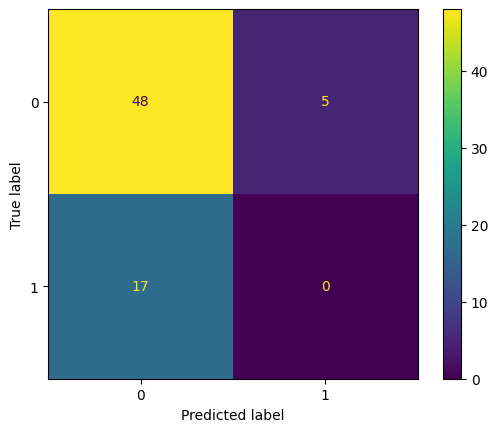

In [ ]:
import matplotlib.pyplot as plt
y_pred=lr.predict(X_test)
from sklearn.metrics import accuracy_score,precision_score,recall_score,confusion_matrix,ConfusionMatrixDisplay
print("Accuracy Score:",accuracy_score(y_pred=y_pred,y_true=y_test))
print("Precision Score:",precision_score(y_pred=y_pred,y_true=y_test,average="macro"))
print("Recall Score:",recall_score(y_pred=y_pred,y_true=y_test,average="macro"))
cm=confusion_matrix(y_pred=y_pred,y_true=y_test)
disp=ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=labels)
disp.plot()
plt.show()

Random Forest Classifiers

In [ ]:
from sklearn.ensemble import RandomForestClassifier
rfc = RandomForestClassifier(
    n_estimators=500,
    class_weight="balanced",
    random_state=42,
)
rfc.fit(X_train,y_train)

RandomForestClassifier(class_weight='balanced', n_estimators=500,
                       random_state=42)

Accuracy Score: 0.7285714285714285
Precision Score: 0.375
Recall Score: 0.4811320754716981


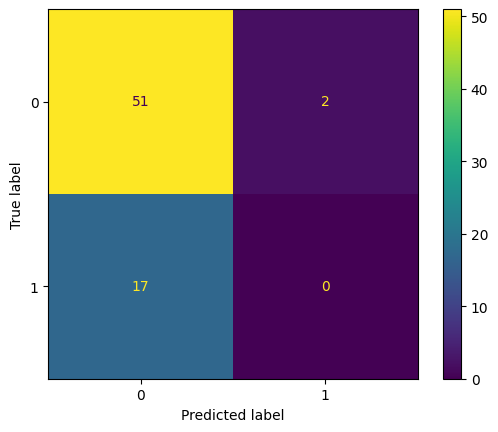

In [ ]:
y_pred=rfc.predict(X_test)
print("Accuracy Score:",accuracy_score(y_pred=y_pred,y_true=y_test))
print("Precision Score:",precision_score(y_pred=y_pred,y_true=y_test,average="macro"))
print("Recall Score:",recall_score(y_pred=y_pred,y_true=y_test,average="macro"))
cm=confusion_matrix(y_pred=y_pred,y_true=y_test)
disp=ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=labels)
disp.plot()
plt.show()

In [ ]:
from sklearn.svm import SVC

svc = SVC(
    kernel="rbf",
    class_weight="balanced",
    # probability=True
)

svc.fit(X_train,y_train)

SVC(class_weight='balanced')

Accuracy Score: 0.45714285714285713
Precision Score: 0.13793103448275862
Recall Score: 0.23529411764705882


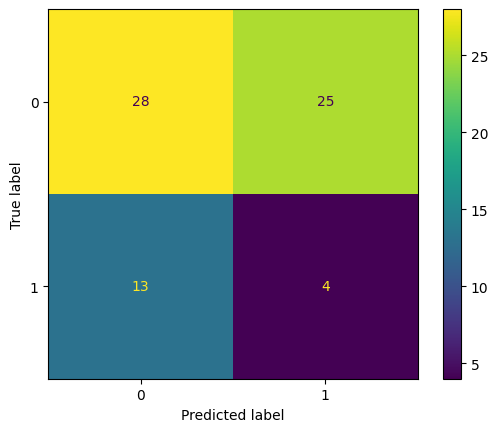

In [ ]:
y_pred=svc.predict(X_test)
print("Accuracy Score:",accuracy_score(y_pred=y_pred,y_true=y_test))
print("Precision Score:",precision_score(y_pred=y_pred,y_true=y_test))
print("Recall Score:",recall_score(y_pred=y_pred,y_true=y_test))
cm=confusion_matrix(y_pred=y_pred,y_true=y_test)
disp=ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=labels)
disp.plot()
plt.show()

Accuracy Score: 0.7142857142857143
Precision Score: 0.0
Recall Score: 0.0


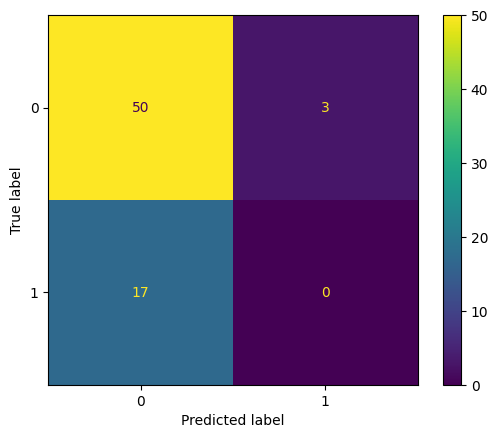

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
knn=KNeighborsClassifier()
knn.fit(X_train,y_train)
y_pred=knn.predict(X_test)
print("Accuracy Score:",accuracy_score(y_pred=y_pred,y_true=y_test))
print("Precision Score:",precision_score(y_pred=y_pred,y_true=y_test))
print("Recall Score:",recall_score(y_pred=y_pred,y_true=y_test))
cm=confusion_matrix(y_pred=y_pred,y_true=y_test)
disp=ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=labels)
disp.plot()
plt.show()

Accuracy Score: 0.7142857142857143
Precision Score: 0.36363636363636365
Recall Score: 0.23529411764705882


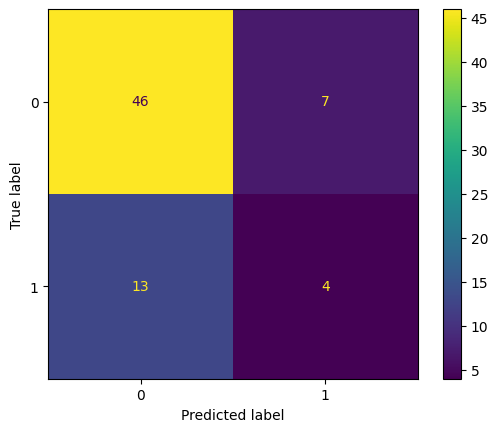

In [ ]:
from sklearn.naive_bayes import GaussianNB
gnb=GaussianNB()
gnb.fit(X_train,y_train)
y_pred=gnb.predict(X_test)
print("Accuracy Score:",accuracy_score(y_pred=y_pred,y_true=y_test))
print("Precision Score:",precision_score(y_pred=y_pred,y_true=y_test))
print("Recall Score:",recall_score(y_pred=y_pred,y_true=y_test))
cm=confusion_matrix(y_pred=y_pred,y_true=y_test)
disp=ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=labels)
disp.plot()
plt.show()

Accuracy Score: 0.6142857142857143
Precision Score: 0.2727272727272727
Recall Score: 0.35294117647058826


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


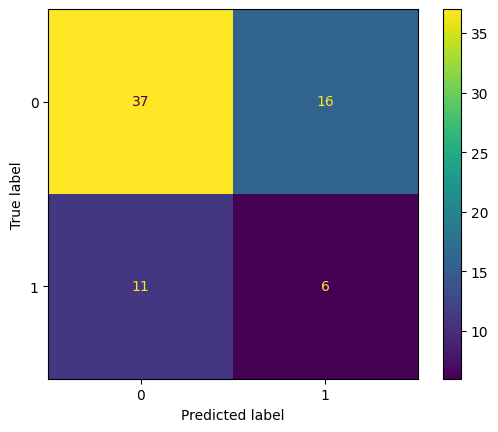

In [ ]:
from sklearn.neural_network import MLPClassifier
mlpc=MLPClassifier(max_iter=500)
mlpc.fit(X_train,y_train)
y_pred=mlpc.predict(X_test)
print("Accuracy Score:",accuracy_score(y_pred=y_pred,y_true=y_test))
print("Precision Score:",precision_score(y_pred=y_pred,y_true=y_test))
print("Recall Score:",recall_score(y_pred=y_pred,y_true=y_test))
cm=confusion_matrix(y_pred=y_pred,y_true=y_test)
disp=ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=labels)
disp.plot()
plt.show()

Decision Tree Classifier

Accuracy Score: 0.6
Precision Score: 0.21052631578947367
Recall Score: 0.23529411764705882


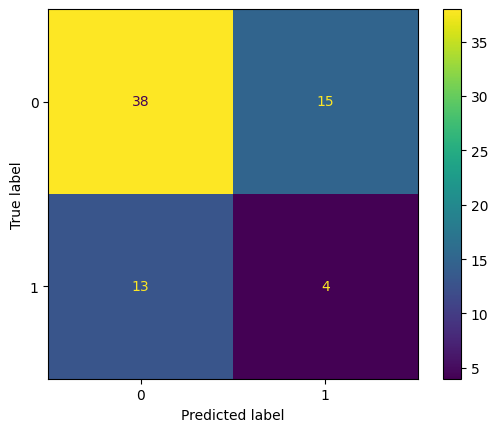

In [ ]:
from sklearn.tree import DecisionTreeClassifier
dtc=DecisionTreeClassifier()
dtc.fit(X_train,y_train)
y_pred=dtc.predict(X_test)
print("Accuracy Score:",accuracy_score(y_pred=y_pred,y_true=y_test))
print("Precision Score:",precision_score(y_pred=y_pred,y_true=y_test))
print("Recall Score:",recall_score(y_pred=y_pred,y_true=y_test))
cm=confusion_matrix(y_pred=y_pred,y_true=y_test)
disp=ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=labels)
disp.plot()
plt.show()

# New attempt


In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("ninadaithal/oasis-1-shinohara")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'oasis-1-shinohara' dataset.
Path to dataset files: /kaggle/input/oasis-1-shinohara


In [ ]:
!ls /kaggle/input/oasis-1-shinohara

oasis  oasis_cross-sectional.csv  oasis_cross-sectional_facts.pdf


In [ ]:
import pandas as pd

In [ ]:
df=pd.read_csv("/kaggle/input/oasis-1-shinohara/oasis_cross-sectional.csv")
df

,ID,M/F,Hand,Age,Educ,SES,MMSE,CDR,eTIV,nWBV,ASF,Delay
0,OAS1_0001_MR1,F,R,74,2.0,3.0,29.0,0.0,1344,0.743,1.306,NaN
1,OAS1_0002_MR1,F,R,55,4.0,1.0,29.0,0.0,1147,0.810,1.531,NaN
2,OAS1_0003_MR1,F,R,73,4.0,3.0,27.0,0.5,1454,0.708,1.207,NaN
3,OAS1_0004_MR1,M,R,28,NaN,NaN,NaN,0.0,1588,0.803,1.105,NaN
4,OAS1_0005_MR1,M,R,18,NaN,NaN,NaN,0.0,1737,0.848,1.010,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
431,OAS1_0285_MR2,M,R,20,NaN,NaN,NaN,0.0,1469,0.847,1.195,2.0
432,OAS1_0353_MR2,M,R,22,NaN,NaN,NaN,0.0,1684,0.790,1.042,40.0
433,OAS1_0368_MR2,M,R,22,NaN,NaN,NaN,0.0,1580,0.856,1.111,89.0
434,OAS1_0379_MR2,F,R,20,NaN,NaN,NaN,0.0,1262,0.861,1.390,2.0


In [ ]:
!ls /kaggle/input/oasis-1-shinohara/oasis/OASIS

OAS1_0001_MR1_mpr_n4_anon_sbj_111_normalised.nii
OAS1_0002_MR1_mpr_n4_anon_sbj_111_normalised.nii
OAS1_0003_MR1_mpr_n4_anon_sbj_111_normalised.nii
OAS1_0004_MR1_mpr_n4_anon_sbj_111_normalised.nii
OAS1_0005_MR1_mpr_n4_anon_sbj_111_normalised.nii
OAS1_0006_MR1_mpr_n4_anon_sbj_111_normalised.nii
OAS1_0007_MR1_mpr_n3_anon_sbj_111_normalised.nii
OAS1_0009_MR1_mpr_n4_anon_sbj_111_normalised.nii
OAS1_0010_MR1_mpr_n4_anon_sbj_111_normalised.nii
OAS1_0011_MR1_mpr_n4_anon_sbj_111_normalised.nii
OAS1_0012_MR1_mpr_n4_anon_sbj_111_normalised.nii
OAS1_0013_MR1_mpr_n4_anon_sbj_111_normalised.nii
OAS1_0014_MR1_mpr_n4_anon_sbj_111_normalised.nii
OAS1_0015_MR1_mpr_n3_anon_sbj_111_normalised.nii
OAS1_0016_MR1_mpr_n3_anon_sbj_111_normalised.nii
OAS1_0017_MR1_mpr_n4_anon_sbj_111_normalised.nii
OAS1_0018_MR1_mpr_n4_anon_sbj_111_normalised.nii
OAS1_0019_MR1_mpr_n4_anon_sbj_111_normalised.nii
OAS1_0020_MR1_mpr_n3_anon_sbj_111_normalised.nii
OAS1_0021_MR1_mpr_n4_anon_sbj_111_normalised.nii
OAS1_0022_MR1_mpr_n4

In [ ]:
import glob
path = "/root/.cache/kagglehub/datasets/ninadaithal/oasis-1-shinohara/versions/2/oasis/OASIS/OAS1_0001_MR1*"

files = glob.glob(path)

for file in files:
    print(file)

/root/.cache/kagglehub/datasets/ninadaithal/oasis-1-shinohara/versions/2/oasis/OASIS/OAS1_0001_MR1_mpr_n4_anon_sbj_111_normalised.nii


In [ ]:
df.isna().sum()

,0
ID,0
M/F,0
Hand,0
Age,0
Educ,201
SES,220
MMSE,201
CDR,0
eTIV,0
nWBV,0


In [ ]:
df=df.drop(labels=["Educ","SES","MMSE","Delay"],axis=1)

In [ ]:
def cdr_map(n):
  return 0 if n==0 else 1
df['CDR']=df["CDR"].map(cdr_map)
df.groupby(['CDR'])['ID'].count()

,ID
CDR,
0,336
1,100


In [ ]:
!pip install nibabel

In [ ]:
import nibabel as nib
import numpy as np
import pandas as pd

from scipy.stats import skew, kurtosis, entropy
from scipy.ndimage import (
    gaussian_filter,
    binary_erosion,
    binary_dilation,
    binary_fill_holes,
)

from skimage.feature import (
    graycomatrix,
    graycoprops,
    local_binary_pattern,
    hog,
)
from skimage.measure import label, regionprops
from skimage.filters import sobel

In [ ]:
DATA_PATH="/root/.cache/kagglehub/datasets/ninadaithal/oasis-1-shinohara/versions/2/oasis/OASIS"
OUTPUT_CSV = "mri_features.csv"

N_HIST_BINS=32
N_GRAY_LEVELS=32
N_SLICES=11
LBP_RADIUS=1
HOG_ORIENTATIONS=9

In [ ]:
import os
len(os.listdir("/root/.cache/kagglehub/datasets/ninadaithal/oasis-1-shinohara/versions/2/oasis/OASIS"))

436

In [ ]:
def safe_float(value):
    """Convert a numeric result to a finite Python float."""
    value = float(value)
    return value if np.isfinite(value) else 0.0


def normalize_intensity(volume, mask):
    """
    Robustly normalize non-background voxels using the 1st and
    99th percentiles. Background remains zero.
    """
    values=volume[mask]

    if values.size == 0:
        raise ValueError("No foreground voxels found.")

    low, high=np.percentile(values,[1, 99])

    normalized=np.zeros(volume.shape,dtype=np.float32)

    if high > low:
        normalized[mask]=np.clip(
            (volume[mask]-low)/(high-low),0,1
        )

    return normalized


def get_slice_indices(length, n_slices=N_SLICES):
    """Select evenly spaced slices across the volume."""
    if length <= 1:
        return [0]

    count = min(n_slices, length)
    return np.unique(
        np.linspace(0, length - 1, count).round().astype(int)
    )


INTENSITY / HISTOGRAM FEATURES

In [ ]:
def extract_intensity_features(volume, mask):
    values = volume[mask].astype(np.float64)

    if values.size == 0:
        raise ValueError("Empty MRI foreground.")

    features = {
        "intensity_mean": np.mean(values),
        "intensity_std": np.std(values),
        "intensity_median": np.median(values),
        "intensity_min": np.min(values),
        "intensity_max": np.max(values),
        "intensity_skewness": skew(values),
        "intensity_kurtosis": kurtosis(values),
        "intensity_iqr": (
            np.percentile(values, 75) -
            np.percentile(values, 25)
        ),
    }

    for p in [1, 5, 10, 25, 75, 90, 95, 99]:
        features[f"intensity_p{p}"] = np.percentile(values, p)

    hist, _ = np.histogram(
        values,
        bins=N_HIST_BINS,
        range=(values.min(), values.max() + 1e-12),
    )

    hist = hist.astype(np.float64)
    hist /= max(hist.sum(), 1)

    for i, value in enumerate(hist):
        features[f"histogram_{i}"] = value

    nonzero_hist = hist[hist > 0]
    features["histogram_entropy"] = entropy(nonzero_hist)

    return {k: safe_float(v) for k, v in features.items()}

3D SHAPE / MORPHOLOGY FEATURES

In [ ]:
def extract_shape_features(mask, voxel_sizes):
    """
    Describes the foreground mask, not anatomical structures
    such as hippocampi or ventricles.
    """
    voxel_volume = float(np.prod(voxel_sizes[:3]))
    coords = np.argwhere(mask)

    features = {
        "foreground_voxel_count": int(mask.sum()),
        "foreground_volume_mm3": float(mask.sum() * voxel_volume),
        "foreground_fraction": float(mask.mean()),
    }

    if coords.size == 0:
        return features

    mins = coords.min(axis=0)
    maxs = coords.max(axis=0)
    extents = maxs - mins + 1

    for axis, name in enumerate(["x", "y", "z"]):
        features[f"bbox_{name}_voxels"] = int(extents[axis])
        features[f"bbox_{name}_mm"] = float(
            extents[axis] * voxel_sizes[axis]
        )

    # Approximate boundary complexity from the mask.
    eroded = binary_erosion(mask)
    boundary = mask & ~eroded

    features["boundary_voxel_count"] = int(boundary.sum())

    # Connected-component information
    components, n_components = label(mask, return_num=True)
    features["connected_components"] = int(n_components)

    return features


3D TEXTURE FEATURES

In [ ]:
def extract_3d_texture_features(volume, mask):
    """
    Computes simple 3D texture descriptors:
    gradient magnitude and local intensity variation.

    These are not 3D GLCM/GLRLM radiomics features.
    """
    features = {}

    smoothed = gaussian_filter(volume, sigma=1)

    gradients = np.gradient(smoothed)
    magnitude = np.sqrt(sum(g ** 2 for g in gradients))

    grad_values = magnitude[mask]

    features["gradient_mean"] = np.mean(grad_values)
    features["gradient_std"] = np.std(grad_values)
    features["gradient_p90"] = np.percentile(grad_values, 90)

    local_mean = gaussian_filter(volume, sigma=2)
    local_sq_mean = gaussian_filter(volume ** 2, sigma=2)

    local_variance = np.maximum(
        local_sq_mean - local_mean ** 2, 0
    )

    local_std = np.sqrt(local_variance[mask])

    features["local_std_mean"] = np.mean(local_std)
    features["local_std_std"] = np.std(local_std)
    features["local_std_p90"] = np.percentile(local_std, 90)

    return {k: safe_float(v) for k, v in features.items()}

2D GLCM FEATURES

In [ ]:
def extract_glcm_features(slice_img, slice_mask):
    """
    GLCM features from one masked 2D slice.
    """
    features = {}

    if slice_mask.sum() < 10:
        return features

    values = slice_img[slice_mask]
    low, high = np.percentile(values, [1, 99])

    if high <= low:
        return features

    quantized = np.zeros(slice_img.shape, dtype=np.uint8)

    quantized[slice_mask] = np.clip(
        ((slice_img[slice_mask] - low) / (high - low)
         * (N_GRAY_LEVELS - 1)),
        0,
        N_GRAY_LEVELS - 1,
    ).astype(np.uint8)

    # Fill masked-out locations with the median quantized intensity.
    # GLCM pairs can still cross the mask boundary; see note below.
    median_level = int(np.median(quantized[slice_mask]))
    quantized[~slice_mask] = median_level

    glcm = graycomatrix(
        quantized,
        distances=[1, 2],
        angles=[0, np.pi / 4, np.pi / 2, 3 * np.pi / 4],
        levels=N_GRAY_LEVELS,
        symmetric=True,
        normed=True,
    )

    for prop in [
        "contrast",
        "dissimilarity",
        "homogeneity",
        "energy",
        "correlation",
        "ASM",
    ]:
        values = graycoprops(glcm, prop)
        features[f"glcm_{prop}_mean"] = values.mean()
        features[f"glcm_{prop}_std"] = values.std()

    return {k: safe_float(v) for k, v in features.items()}

2D LBP FEATURES

In [ ]:
def extract_lbp_features(slice_img, slice_mask):
    features = {}

    if slice_mask.sum() < 10:
        return features

    values = slice_img[slice_mask]
    low, high = np.percentile(values, [1, 99])

    scaled = np.zeros(slice_img.shape, dtype=np.uint8)

    if high > low:
        scaled[slice_mask] = np.clip(
            (slice_img[slice_mask] - low) / (high - low) * 255,
            0,
            255,
        ).astype(np.uint8)

    lbp = local_binary_pattern(
        scaled,
        P=8 * LBP_RADIUS,
        R=LBP_RADIUS,
        method="uniform",
    )

    n_bins = 8 * LBP_RADIUS + 2

    hist, _ = np.histogram(
        lbp[slice_mask],
        bins=np.arange(n_bins + 1),
        density=False,
    )

    hist = hist.astype(np.float64)
    hist /= max(hist.sum(), 1)

    for i, value in enumerate(hist):
        features[f"lbp_{i}"] = value

    return features

2D HOG FEATURES

In [ ]:
def extract_hog_features(slice_img, slice_mask):
    """
    Summarizes HOG across a slice to keep feature dimensionality
    manageable and independent of the exact slice size.
    """
    features = {}

    if slice_mask.sum() < 10:
        return features

    values = slice_img[slice_mask]
    low, high = np.percentile(values, [1, 99])

    scaled = np.zeros(slice_img.shape, dtype=np.float32)

    if high > low:
        scaled[slice_mask] = np.clip(
            (slice_img[slice_mask] - low) / (high - low), 0, 1
        )

    hog_vector = hog(
        scaled,
        orientations=HOG_ORIENTATIONS,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys",
        feature_vector=True,
    )

    features["hog_mean"] = np.mean(hog_vector)
    features["hog_std"] = np.std(hog_vector)
    features["hog_p90"] = np.percentile(hog_vector, 90)
    features["hog_energy"] = np.sum(hog_vector ** 2)

    return {k: safe_float(v) for k, v in features.items()}

MULTI-PLANE SLICE FEATURES

In [ ]:
def extract_multiplane_features(volume, mask):
    """
    Extract features from evenly spaced sagittal, coronal and
    axial slices, then aggregate slice features by mean/std/max.
    """
    features = {}

    # Arrays are assumed to use their existing NIfTI voxel axes.
    # Axis labels here refer to array planes, not guaranteed
    # anatomical directions without orientation inspection.
    planes = {
        "plane0": (0, lambda i: (volume[i, :, :], mask[i, :, :])),
        "plane1": (1, lambda i: (volume[:, i, :], mask[:, i, :])),
        "plane2": (2, lambda i: (volume[:, :, i], mask[:, :, i])),
    }

    for plane_name, (axis, get_slice) in planes.items():
        indices = get_slice_indices(volume.shape[axis])

        all_slice_features = []

        for i in indices:
            slice_img, slice_mask = get_slice(i)

            # Skip mostly empty slices.
            if slice_mask.mean() < 0.02 or slice_mask.sum() < 10:
                continue

            slice_features = {}

            slice_features.update(
                extract_glcm_features(slice_img, slice_mask)
            )
            slice_features.update(
                extract_lbp_features(slice_img, slice_mask)
            )
            slice_features.update(
                extract_hog_features(slice_img, slice_mask)
            )

            if slice_features:
                all_slice_features.append(slice_features)

        if not all_slice_features:
            continue

        df = pd.DataFrame(all_slice_features)

        for column in df.columns:
            features[f"{plane_name}_{column}_mean"] = safe_float(
                df[column].mean()
            )
            features[f"{plane_name}_{column}_std"] = safe_float(
                df[column].std()
            )
            features[f"{plane_name}_{column}_max"] = safe_float(
                df[column].max()
            )

    return features

PROCESS ONE MRI

In [ ]:
def extract_features_from_nii(file_path):
    nii = nib.load(str(file_path))

    # Apply NIfTI intensity scaling using NiBabel.
    volume = nii.get_fdata(dtype=np.float32)

    if volume.ndim != 3:
        raise ValueError(
            f"Expected a 3D MRI, got shape {volume.shape}"
        )

    if not np.isfinite(volume).all():
        volume = np.nan_to_num(volume, copy=False)

    voxel_sizes = nii.header.get_zooms()[:3]

    # For skull-stripped scans, zero is commonly background.
    # If valid brain voxels can be zero/negative, use an explicit
    # brain mask instead of this threshold.
    mask = volume != 0

    if mask.sum() == 0:
        raise ValueError("Volume has no nonzero voxels.")

    normalized = normalize_intensity(volume, mask)

    features = {
        # "file_name": file_path.name,
        "shape_x": volume.shape[0],
        "shape_y": volume.shape[1],
        "shape_z": volume.shape[2],
        "voxel_size_x_mm": voxel_sizes[0],
        "voxel_size_y_mm": voxel_sizes[1],
        "voxel_size_z_mm": voxel_sizes[2],
    }

    features.update(
        extract_intensity_features(normalized, mask)
    )
    features.update(
        extract_shape_features(mask, voxel_sizes)
    )
    features.update(
        extract_3d_texture_features(normalized, mask)
    )
    features.update(
        extract_multiplane_features(normalized, mask)
    )

    return features

In [ ]:
dataset=dict()
dataset['ID']=[]
for col in df['ID']:
  path=os.path.join(DATA_PATH,col+'*')
  files = glob.glob(path)
  file_path=files[0]
  features=extract_features_from_nii(file_path)
  dataset['ID'].append(col)
  for key in features:
    if key not in dataset:
      dataset[key]=[]
    dataset[key].append(features[key])
feature_df=pd.DataFrame(dataset)
feature_df.to_csv(OUTPUT_CSV, index=False)

In [ ]:
feature_df=pd.read_csv("/content/mri_features.csv")

In [ ]:
df['M/F']=df['M/F'].map(lambda x: 1 if x=='M' else 0)
df['Hand']=df['Hand'].map(lambda x: 1 if x=='R' else 0)
complete_dataset=pd.merge(feature_df,df,on='ID')
complete_dataset

,ID,shape_x,shape_y,shape_z,voxel_size_x_mm,voxel_size_y_mm,voxel_size_z_mm,intensity_mean,intensity_std,intensity_median,...,plane2_hog_energy_mean,plane2_hog_energy_std,plane2_hog_energy_max,M/F,Hand,Age,CDR,eTIV,nWBV,ASF
0,OAS1_0001_MR1,91,109,91,2.0,2.0,2.0,0.431118,0.219231,0.452941,...,93.250,26.233839,114.0,0,1,74,0,1344,0.743,1.306
1,OAS1_0002_MR1,91,109,91,2.0,2.0,2.0,0.586792,0.274515,0.619192,...,94.250,22.745486,114.0,0,1,55,0,1147,0.810,1.531
2,OAS1_0003_MR1,91,109,91,2.0,2.0,2.0,0.560856,0.288888,0.591746,...,89.875,26.438270,115.0,0,1,73,1,1454,0.708,1.207
3,OAS1_0004_MR1,91,109,91,2.0,2.0,2.0,0.566010,0.274532,0.569207,...,93.000,24.418962,116.0,1,1,28,0,1588,0.803,1.105
4,OAS1_0005_MR1,91,109,91,2.0,2.0,2.0,0.604228,0.266565,0.617537,...,92.250,26.201145,115.0,1,1,18,0,1737,0.848,1.010
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
431,OAS1_0285_MR2,91,109,91,2.0,2.0,2.0,0.580907,0.262625,0.591114,...,91.000,27.557732,115.0,1,1,20,0,1469,0.847,1.195
432,OAS1_0353_MR2,91,109,91,2.0,2.0,2.0,0.569721,0.274739,0.577730,...,92.500,25.219040,116.0,1,1,22,0,1684,0.790,1.042
433,OAS1_0368_MR2,91,109,91,2.0,2.0,2.0,0.596546,0.272782,0.606007,...,91.875,26.416648,115.0,1,1,22,0,1580,0.856,1.111
434,OAS1_0379_MR2,91,109,91,2.0,2.0,2.0,0.595711,0.275716,0.610484,...,94.000,25.455844,115.0,0,1,20,0,1262,0.861,1.390


In [ ]:
y=complete_dataset['CDR']
X=complete_dataset.drop(labels=['ID','CDR'],axis=1)

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

ss=StandardScaler()
pca=PCA(n_components=80)

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
X_train_scaled=ss.fit_transform(X_train)
X_test_scaled=ss.fit_transform(X_test)
X_train_pca=pca.fit_transform(X_train_scaled)
X_test_pca=pca.fit_transform(X_test_scaled)



/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Accuracy Score: 0.6363636363636364
Precision Score: 0.4391052195526098
Recall Score: 0.4439359267734554


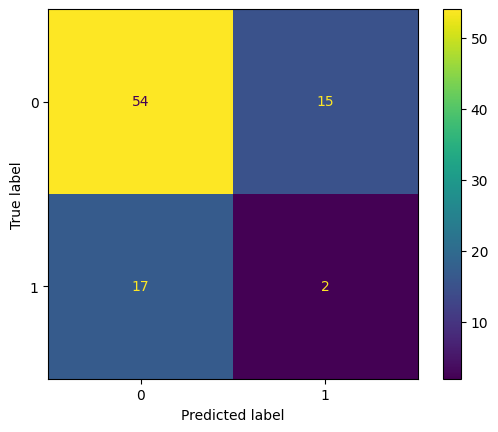

In [ ]:
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt
lr=LogisticRegression(max_)
lr.fit(X_train_pca,y_train)
y_pred=lr.predict(X_test_pca)
from sklearn.metrics import accuracy_score,precision_score,recall_score,confusion_matrix,ConfusionMatrixDisplay
print("Accuracy Score:",accuracy_score(y_pred=y_pred,y_true=y_test))
print("Precision Score:",precision_score(y_pred=y_pred,y_true=y_test,average="macro"))
print("Recall Score:",recall_score(y_pred=y_pred,y_true=y_test,average="macro"))
cm=confusion_matrix(y_pred=y_pred,y_true=y_test)
disp=ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=[0,1])
disp.plot()
plt.show()